#Surface by surface simulation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from utilities import make_grid, angular_spectrum, pupil, plot_field
from ilumination import source_field, source_spectrum, mirror_pupil

###Source

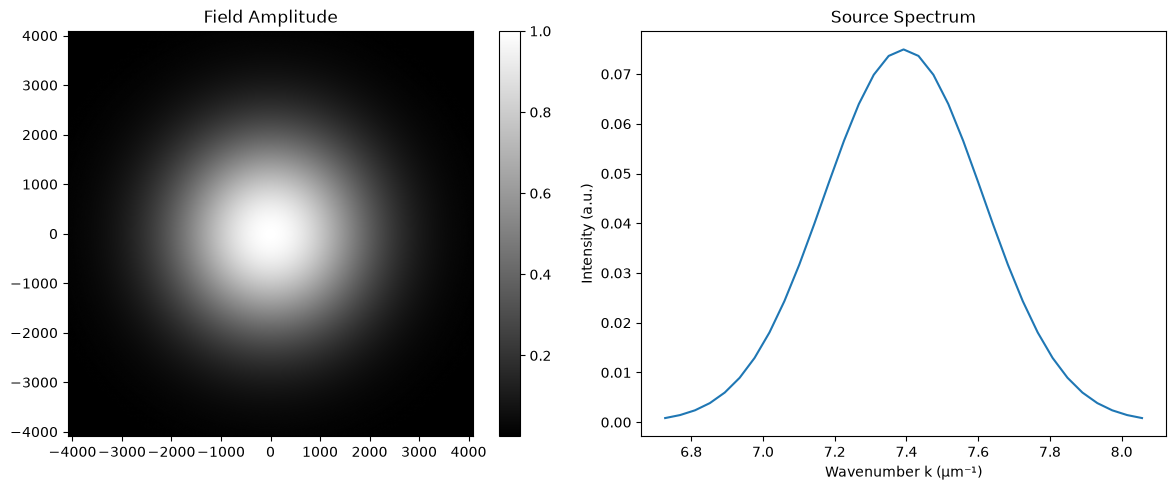

In [3]:
central_lam = 0.850 # central wavelength in micrometers
fwhm = 0.06  # full width at half maximum in micrometers
n = np.array([4096, 4096])
dx, dy = 2, 2
w0 = 2e3

X, Y = make_grid(n, dx, dy)
U_source = source_field(X, Y, central_lam, w0)
S_source = source_spectrum(central_lam, fwhm, n_k=33)

#Plot field amplitude and phase
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(U_source), extent=[X.min(), X.max(), Y.min(), Y.max()], cmap='gray')
plt.title('Field Amplitude')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(S_source[0], S_source[1])
plt.title('Source Spectrum')
plt.xlabel('Wavenumber k (µm⁻¹)')
plt.ylabel('Intensity (a.u.)')

plt.tight_layout()
plt.show()

###Just before mirror

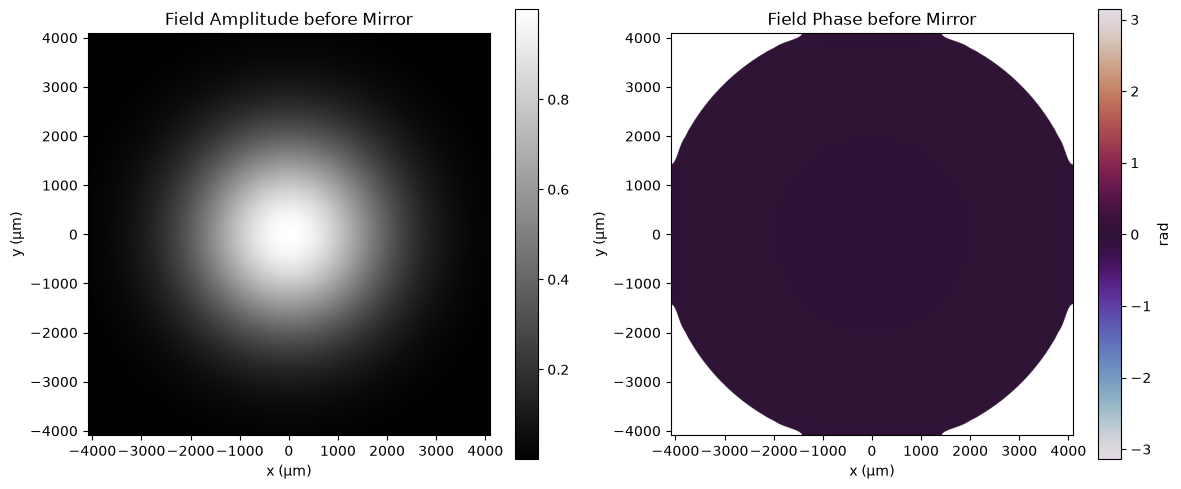

In [5]:
z_M1 = 50e3  # distance to mirror in micrometers

U_M1_ = angular_spectrum(U_source, dx=dx, dy=dy, z=z_M1, lam=central_lam)

plot_field(U_M1_, X, Y, 'before Mirror', z=z_M1, lam=central_lam)

###Just after mirror

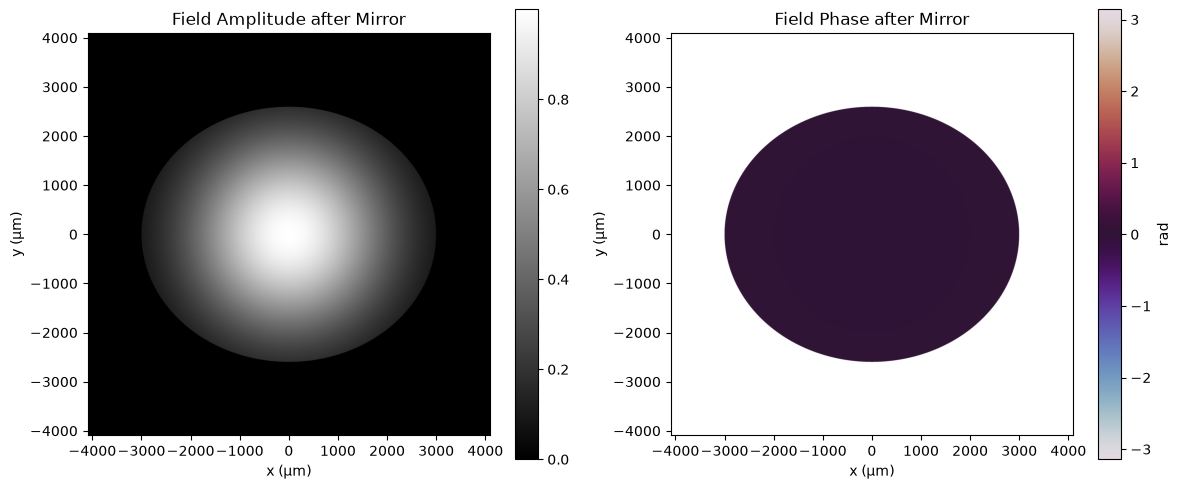

In [6]:
M1_r = 3e3 # Mirror 1 radius in micrometers
M1_theta = 30
P_M1 = mirror_pupil(X, Y, M1_r, M1_theta)

U_M1 = U_M1_ * P_M1

plot_field(U_M1, X, Y, 'after Mirror', z=z_M1, lam=central_lam)

###Just before sample

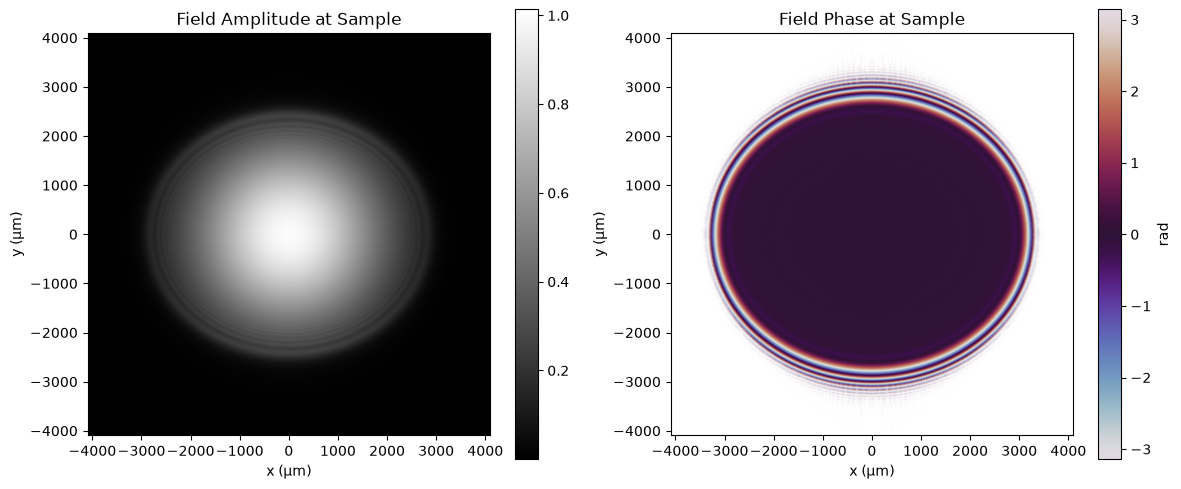

In [7]:
z_sample = 50e3  # distance to sample in micrometers
U_sample = angular_spectrum(U_M1, dx=dx, dy=dy, z=z_sample, lam=central_lam)

plot_field(U_sample, X, Y, 'at Sample', z=z_M1 + z_sample, lam=central_lam)

###Just after sample

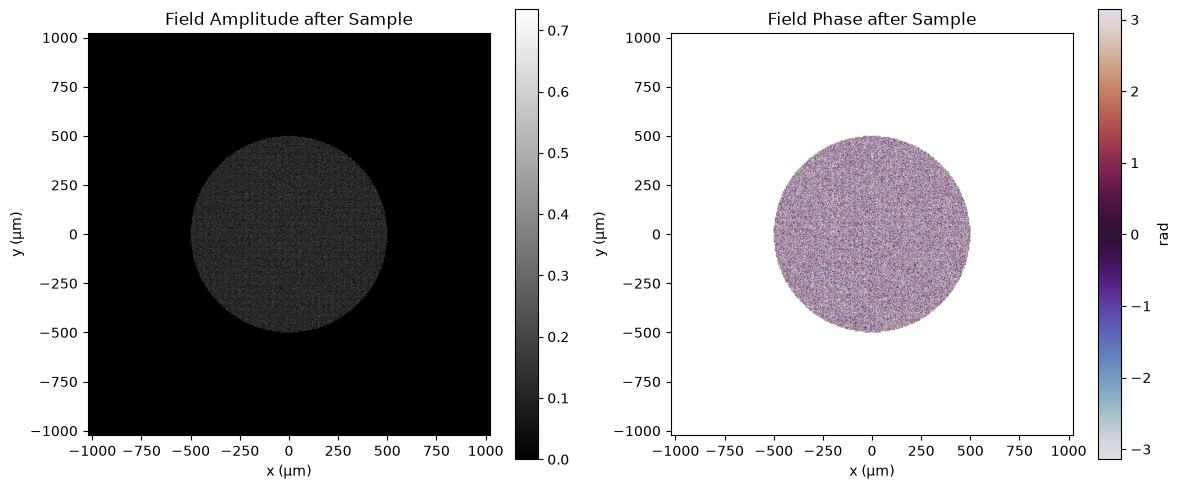

In [8]:
import numpy as np
from doppler_scattering import scattering_vector, mie_amplitude, object_amplitudes, field_after_sample

from pathlib import Path

DPD = Path.cwd().parents[1] / "DPD tissue" / "code"

trajs = [dict(np.load(DPD / "runs" / f"cell_{k}" / "traj.npz")) for k in range(4)]
layout = dict(np.load(DPD / "layout.npz"))
q, theta_s = scattering_vector()                    # n = 1.36: |q| ≈ 19.3 µm⁻¹
S_name = {"nucleus": mie_amplitude(1.0, 1.39, 1.36, theta_s),
          "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, theta_s),
          "vesicle": mie_amplitude(0.25, 1.40, 1.36, theta_s)}
amps = object_amplitudes(layout, trajs, S_name)      # once
s = slice(n[0]//2 - 512, n[0]//2 + 512)            # 1024 x 1024 px = 2 mm, contains the 1 mm disk
U_ill, Xc, Yc = U_sample[s, s], X[s, s], Y[s, s]
U_after = field_after_sample(0, U_ill, Xc, Yc, layout, trajs, amps, q)

plot_field(U_after, Xc, Yc, 'after Sample', z=z_M1 + z_sample, lam=central_lam)

###Image plane (objective 2f-2f)

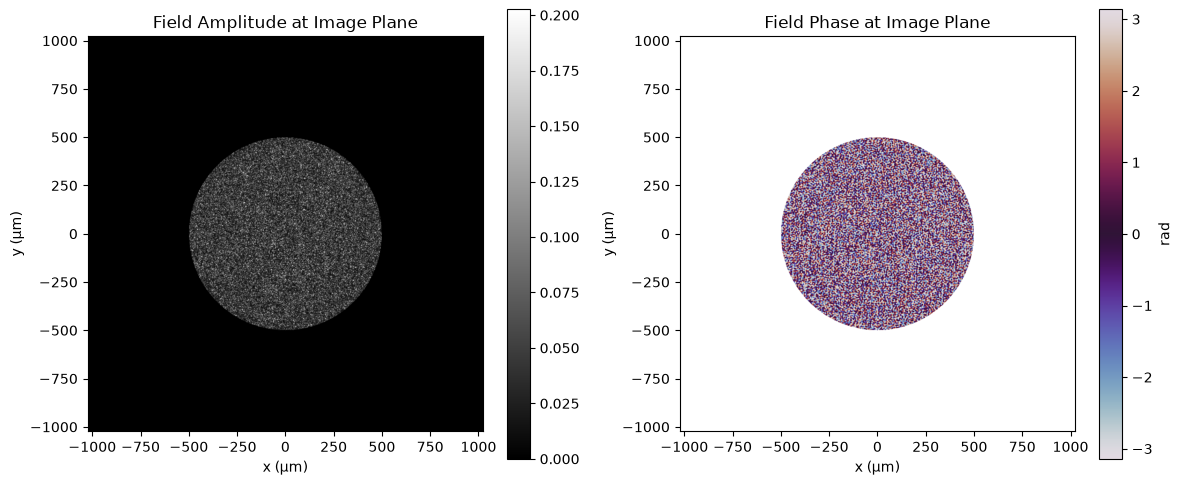

In [9]:
from collection import lens_transmitance
from utilities import fresnel_fft

f1, R1 = 75e3, 12.7e3          # objective focal length and radius (1-inch lens assumed)
R_IP = 500                     # field stop at the image plane

U_L1_, X1, Y1 = fresnel_fft(U_after, Xc, Yc, central_lam, 2*f1)     # just before objective
U_L1 = U_L1_ * lens_transmitance(X1, Y1, f1, central_lam, R1)        # just after objective
U_IP_, Xi, Yi = fresnel_fft(U_L1, X1, Y1, central_lam, 2*f1)        # image plane
U_IP = U_IP_ * pupil(Xi, Yi, R_IP)

plot_field(U_IP, Xi, Yi, 'at Image Plane')

###Camera (Fourier lens + biprism)

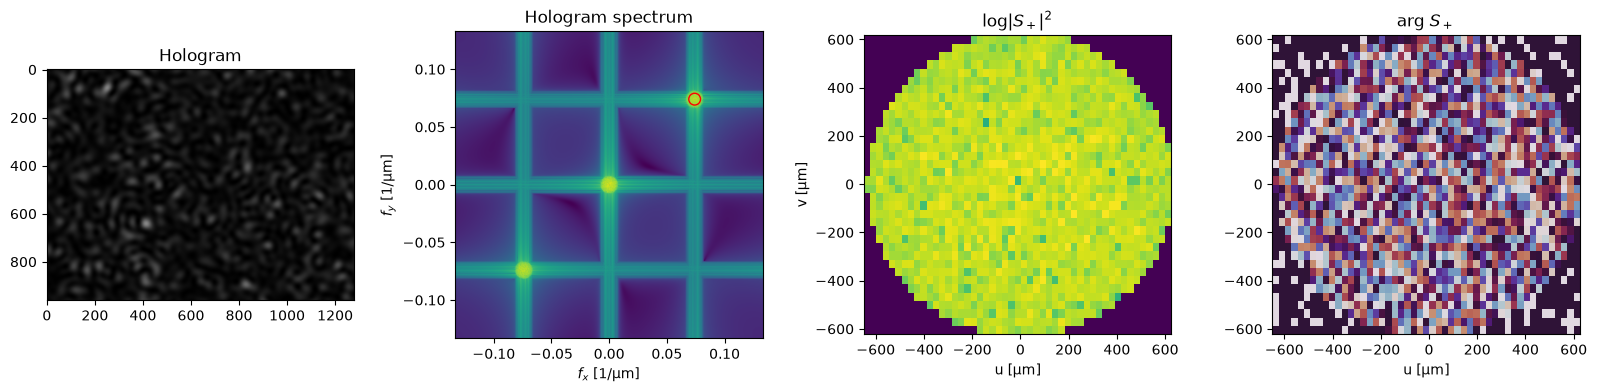

sideband pixels: 1406


In [ ]:
from collection import camera_hologram
from matplotlib.patches import Circle

f2 = 150e3
theta = 0.51 * np.radians(5) # (n_g - 1) * beta, with apex 169° (5.5°)
d_B = 140e3
p = 3.75
xc = (np.arange(1280) - 640) * p
yc = (np.arange(960) - 480) * p
Lambda = central_lam / (2 * theta)
I = camera_hologram(U_IP, Xi, Yi, central_lam, f2, xc, yc, theta, d_B)

#Save the hologram to an image file
plt.imsave('hologram.png', I, cmap='gray')

# Spectrum of the hologram and its frequency axes [1/µm]
F = np.fft.fftshift(np.fft.fft2(I - I.mean()))
fx = np.fft.fftshift(np.fft.fftfreq(I.shape[1], p))
fy = np.fft.fftshift(np.fft.fftfreq(I.shape[0], p))

# Carrier along the biprism normal and the sideband radius
c = np.array([np.cos(np.radians(45)), np.sin(np.radians(45))]) / Lambda
r_sb = 1.3 * R_IP / (central_lam * f2)

# Crop a box around the carrier, then mask it to a disk
ix = np.abs(fx - c[0]) <= r_sb
iy = np.abs(fy - c[1]) <= r_sb
FX, FY = np.meshgrid(fx[ix], fy[iy])
F_sb = F[np.ix_(iy, ix)] * (np.hypot(FX - c[0], FY - c[1]) <= r_sb)

# Fourier-plane coordinates mapped back to image-plane µm: u = λ f2 (f - c)
ext = central_lam * f2 * np.array([fx[ix][0] - c[0], fx[ix][-1] - c[0],
                                   fy[iy][0] - c[1], fy[iy][-1] - c[1]])

plt.figure(figsize=(16, 4.5))
plt.subplot(1, 4, 1); plt.imshow(I, cmap='gray'); plt.title('Hologram')
ax = plt.subplot(1, 4, 2)
plt.imshow(np.log10(np.abs(F)**2 + 1e-12), origin='lower',
           extent=[fx[0], fx[-1], fy[0], fy[-1]])
ax.add_patch(Circle(c, r_sb, fill=False, color='r'))
plt.xlabel(r'$f_x$ [1/µm]'); plt.ylabel(r'$f_y$ [1/µm]'); plt.title('Hologram spectrum')
plt.subplot(1, 4, 3)
plt.imshow(np.log10(np.abs(F_sb)**2 + 1e-12), origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.ylabel('v [µm]'); plt.title(r'$\log|S_+|^2$')
plt.subplot(1, 4, 4)
plt.imshow(np.angle(F_sb), cmap='twilight', origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.title(r'arg $S_+$')
plt.tight_layout(); plt.show()
print(f'sideband pixels: {np.count_nonzero(F_sb)}') 

###Time series and field spectrum

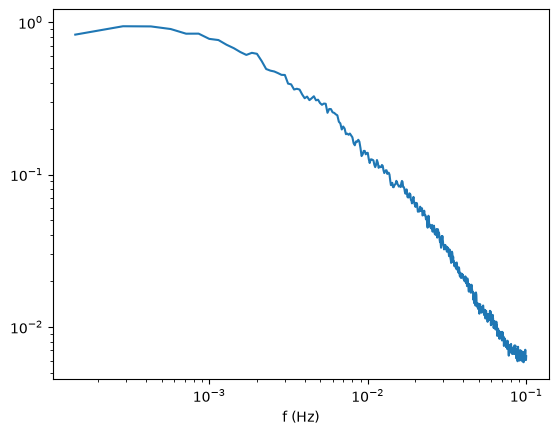

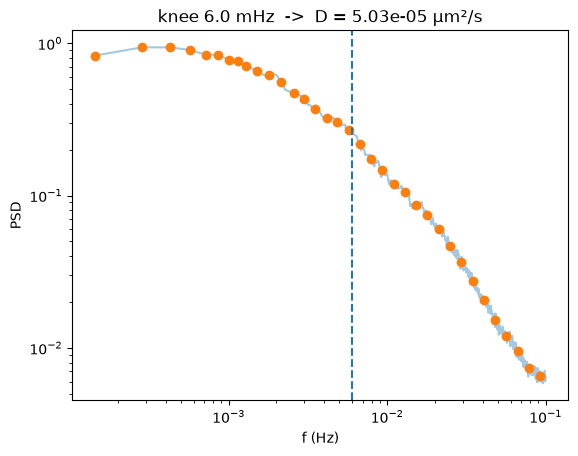

In [ ]:
from spectrum import field_spectrum, log_bin, knee_frequency
from collection import sideband
from tqdm.auto import tqdm

n_frames = 1400
S = []
for k in tqdm(range(n_frames), desc='Holograms'):
    U_after = field_after_sample(k, U_ill, Xc, Yc, layout, trajs, amps, q)
    U_L1, X1, Y1 = fresnel_fft(U_after, Xc, Yc, central_lam, 2*f1)
    U_L1 *= lens_transmitance(X1, Y1, f1, central_lam, R1)
    U_IP, Xi, Yi = fresnel_fft(U_L1, X1, Y1, central_lam, 2*f1)
    U_IP *= pupil(Xi, Yi, R_IP)
    I = camera_hologram(U_IP, Xi, Yi, central_lam, f2, xc, yc, theta, d_B)
    S.append(sideband(I, p, Lambda, radius=1.3 * R_IP / (central_lam * f2)))   # whole sideband disk, every pixel
    
    # Checkpoint every 100 frames
    if (k + 1) % 100 == 0:
        np.save('S_checkpoint.npy', np.array(S))

S = np.array(S)                                      # (frames, pixels)
np.save('S_final.npy', S)

S = np.load('S_final.npy')                          # load the precomputed sideband data
f, P = field_spectrum(S)
plt.loglog(f, P); plt.xlabel('f (Hz)'); plt.show()

fk = knee_frequency(f, P)
D = np.pi * fk / np.linalg.norm(q)**2              # |q| ≈ 19.3 µm⁻¹ in cytoplasm

plt.loglog(f, P, alpha=0.4)
plt.loglog(*log_bin(f, P), 'o')
plt.axvline(fk, ls='--')
plt.xlabel('f (Hz)'); plt.ylabel('PSD')
plt.title(f'knee {fk*1e3:.1f} mHz  ->  D = {D:.2e} µm²/s')
plt.show()

###Broadband source: one time series per wavelength

In [16]:
from pathlib import Path
from utilities import make_grid, fresnel_fft
from collection import lens_transmitance, camera_hologram, sideband
from doppler_scattering import scattering_vector, mie_amplitude, object_amplitudes, field_after_sample
from tqdm.auto import tqdm

k_src, w_src = S_source
lam_src = 2 * np.pi / k_src
j0 = np.argmin(np.abs(lam_src - central_lam))           # the wavelength already simulated
assert np.isclose(lam_src[j0], central_lam)

# Processing is fixed by the camera, not the wavelength: same carrier window for every λ
r_sb = 1.3 * R_IP / (central_lam * f2)
n_sb = sideband(np.zeros((len(yc), len(xc))), p, Lambda, radius=r_sb).size

out = Path('S_lambda'); out.mkdir(exist_ok=True)

# Files made with other optics/window parameters cannot be summed with new ones: set them aside
for path in out.glob('S_*.npy'):
    if np.load(path, mmap_mode='r').shape != (n_frames, n_sb):
        path.rename(path.with_suffix('.stale'))
        print(f'{path.name}: different window, moved to {path.with_suffix(".stale").name}')

# Reuse the central run from cell 17 only if it matches the current window
if not (out / f'S_{j0:02d}.npy').exists():
    if np.load('S_final.npy', mmap_mode='r').shape == (n_frames, n_sb):
        np.save(out / f'S_{j0:02d}.npy', np.load('S_final.npy'))
    else:
        print('S_final.npy does not match the current window, the central λ will be rerun')

N = U_ill.shape[0]
dxc = Xc[0, 1] - Xc[0, 0]

# Closest to the centre first, so a partial run already covers most of the spectral weight
for j in np.argsort(np.abs(np.arange(len(lam_src)) - j0)):
    lam = lam_src[j]
    path = out / f'S_{j:02d}.npy'
    if path.exists():
        continue

    # Illumination at this wavelength (same optics as the cells above)
    U = source_field(X, Y, lam, w0)
    U = angular_spectrum(U, dx=dx, dy=dy, z=z_M1, lam=lam) * P_M1
    U = angular_spectrum(U, dx=dx, dy=dy, z=z_sample, lam=lam)
    U_ill_j = U[s, s]
    del U

    # Scattering vector and Mie amplitudes at this wavelength
    q_j, th_j = scattering_vector(lam0=lam)
    amps_j = object_amplitudes(layout, trajs, {
        "nucleus": mie_amplitude(1.0, 1.39, 1.36, th_j, lam0=lam),
        "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, th_j, lam0=lam),
        "vesicle": mie_amplitude(0.25, 1.40, 1.36, th_j, lam0=lam)})

    # Grids and masks that depend only on λ (the same grids fresnel_fft would return)
    d1 = lam * 2 * f1 / (N * dxc)
    X1_j, Y1_j = make_grid((N, N), d1, d1)
    di = lam * 2 * f1 / (N * d1)
    Xi_j, Yi_j = make_grid((N, N), di, di)
    L1 = lens_transmitance(X1_j, Y1_j, f1, lam, R1)
    P_IP = pupil(Xi_j, Yi_j, R_IP)

    S_j = np.empty((n_frames, n_sb), dtype=complex)
    for k in tqdm(range(n_frames), desc=f'λ = {lam*1e3:.1f} nm ({j})', leave=False):
        U_after = field_after_sample(k, U_ill_j, Xc, Yc, layout, trajs, amps_j, q_j)
        U_L1, _, _ = fresnel_fft(U_after, Xc, Yc, lam, 2*f1)
        U_IP, _, _ = fresnel_fft(U_L1 * L1, X1_j, Y1_j, lam, 2*f1)
        I = camera_hologram(U_IP * P_IP, Xi_j, Yi_j, lam, f2, xc, yc, theta, d_B)
        S_j[k] = sideband(I, p, Lambda, radius=r_sb)

    np.save(path, S_j)

KeyboardInterrupt: 

###Broadband Doppler spectrum

27/33 wavelengths, 99.1% of the source power


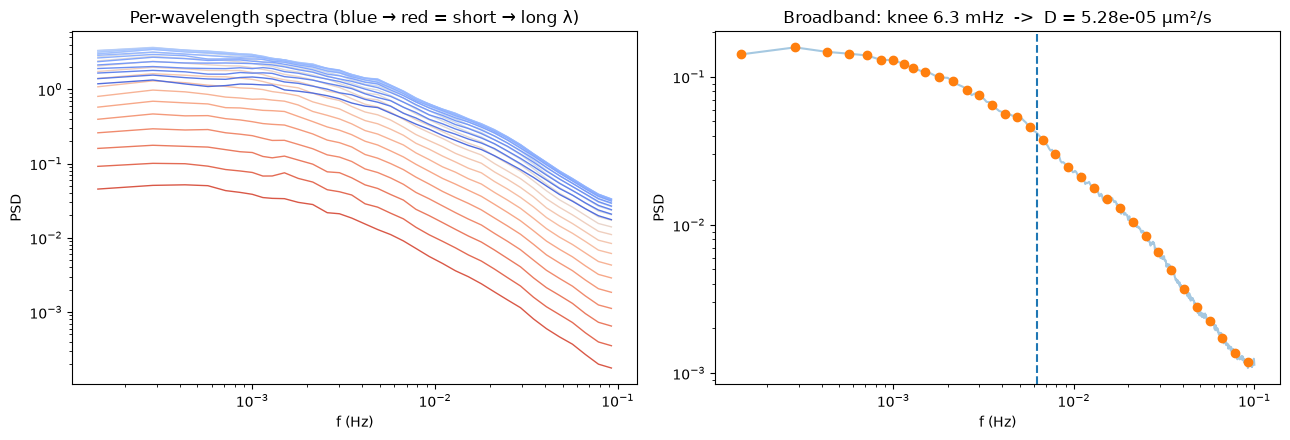

In [17]:
avail = [j for j in range(len(lam_src)) if (out / f'S_{j:02d}.npy').exists()]
w = w_src[avail] / w_src[avail].sum()
print(f'{len(avail)}/{len(lam_src)} wavelengths, {w_src[avail].sum()*100:.1f}% of the source power')

# The camera adds intensities incoherently and sideband() is linear in I, so S+ adds with weights S(λ)
S_tot = 0
plt.figure(figsize=(13, 4.5))
plt.subplot(1, 2, 1)
for wj, j in zip(w, avail):
    S_j = np.load(out / f'S_{j:02d}.npy')
    S_tot = S_tot + wj * S_j
    f, P_j = field_spectrum(S_j)
    plt.loglog(*log_bin(f, P_j), color=plt.cm.coolwarm((lam_src[j] - lam_src.min()) / np.ptp(lam_src)), lw=1)
plt.xlabel('f (Hz)'); plt.ylabel('PSD'); plt.title('Per-wavelength spectra (blue → red = short → long λ)')

f, P = field_spectrum(S_tot)
fk = knee_frequency(f, P)

# Effective |q|^2 of the broadband measurement
q2_eff = sum(wj * np.sum(scattering_vector(lam0=lam_src[j])[0]**2) for wj, j in zip(w, avail))
D = np.pi * fk / q2_eff

plt.subplot(1, 2, 2)
plt.loglog(f, P, alpha=0.4)
plt.loglog(*log_bin(f, P), 'o')
plt.axvline(fk, ls='--')
plt.xlabel('f (Hz)'); plt.ylabel('PSD')
plt.title(f'Broadband: knee {fk*1e3:.1f} mHz  ->  D = {D:.2e} µm²/s')
plt.tight_layout(); plt.show()
np.save('S_broadband.npy', S_tot)

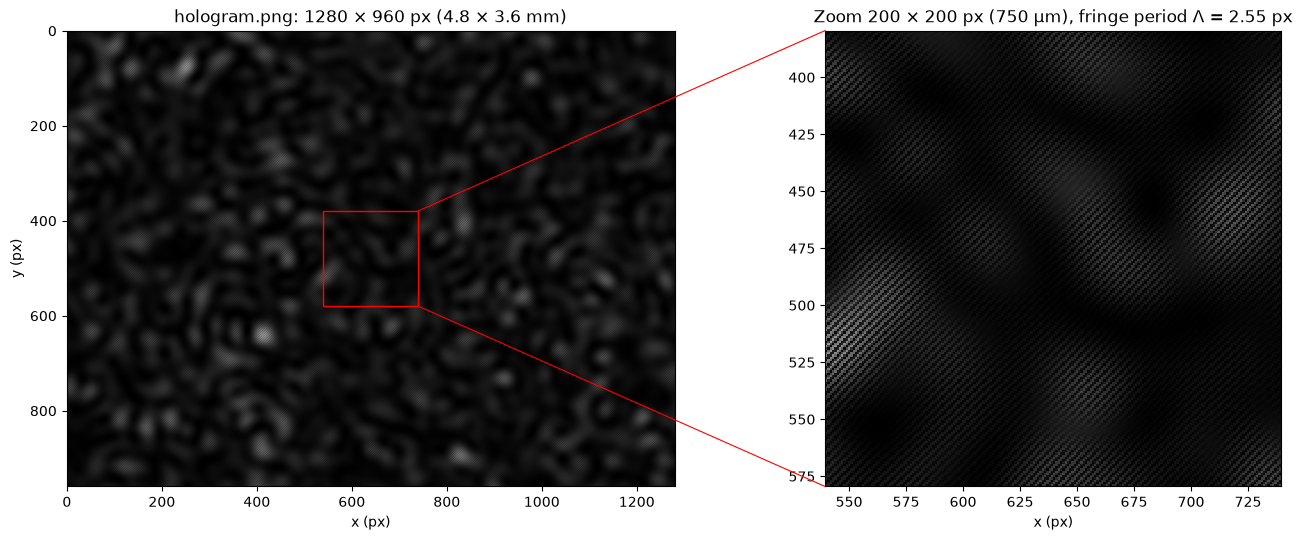

In [13]:
FILE = 'hologram.png'     # or 'hologram150.png'
CX, CY = None, None       # zoom centre in pixels (None = image centre)
W = 100                    # zoom half-width in pixels (64 x 64 px crop)

img = plt.imread(FILE)[..., 0]           # imsave with a gray cmap stores R = G = B, keep one channel
ny, nx = img.shape
cx = nx // 2 if CX is None else CX
cy = ny // 2 if CY is None else CY

fig, (ax, axz) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [nx / ny, 1]})

ax.imshow(img, cmap='gray')
ax.set(title=f'{FILE}: {nx} × {ny} px ({nx * p / 1e3:.1f} × {ny * p / 1e3:.1f} mm)',
       xlabel='x (px)', ylabel='y (px)')

# Same image, nearest-neighbour so single camera pixels stay visible, limited to the zoom window
axz.imshow(img, cmap='gray', interpolation='nearest')
axz.set_xlim(cx - W - 0.5, cx + W - 0.5)
axz.set_ylim(cy + W - 0.5, cy - W - 0.5)          # reversed so up/down matches the full image
axz.set(title=f'Zoom {2*W} × {2*W} px ({2 * W * p:.0f} µm), fringe period Λ = {Lambda / p:.2f} px',
        xlabel='x (px)')

from matplotlib.patches import Rectangle, ConnectionPatch

# Zoom window in data coordinates, the same numbers on both axes
x0, x1 = cx - W - 0.5, cx + W - 0.5
y0, y1 = cy - W - 0.5, cy + W - 0.5
ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='r', lw=1))

# Right edge of the box -> left edge of the zoom, top to top and bottom to bottom
for y in (y0, y1):
    fig.add_artist(ConnectionPatch((x1, y), (x0, y), 'data', 'data',
                                   axesA=ax, axesB=axz, color='r', lw=0.8))

fig.tight_layout()
plt.show()


c:\Users\andre\iCloudDrive\Uni\Semestre 7\Avanzado\Simulation_BioTissue_FBDHS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Wavelengths: 100%|██████████| 33/33 [08:03<00:00, 14.64s/it]


coherence length λ²/Δλ = 12.0 µm  ->  about 14 fringes, a band about 36 px wide across the fringes


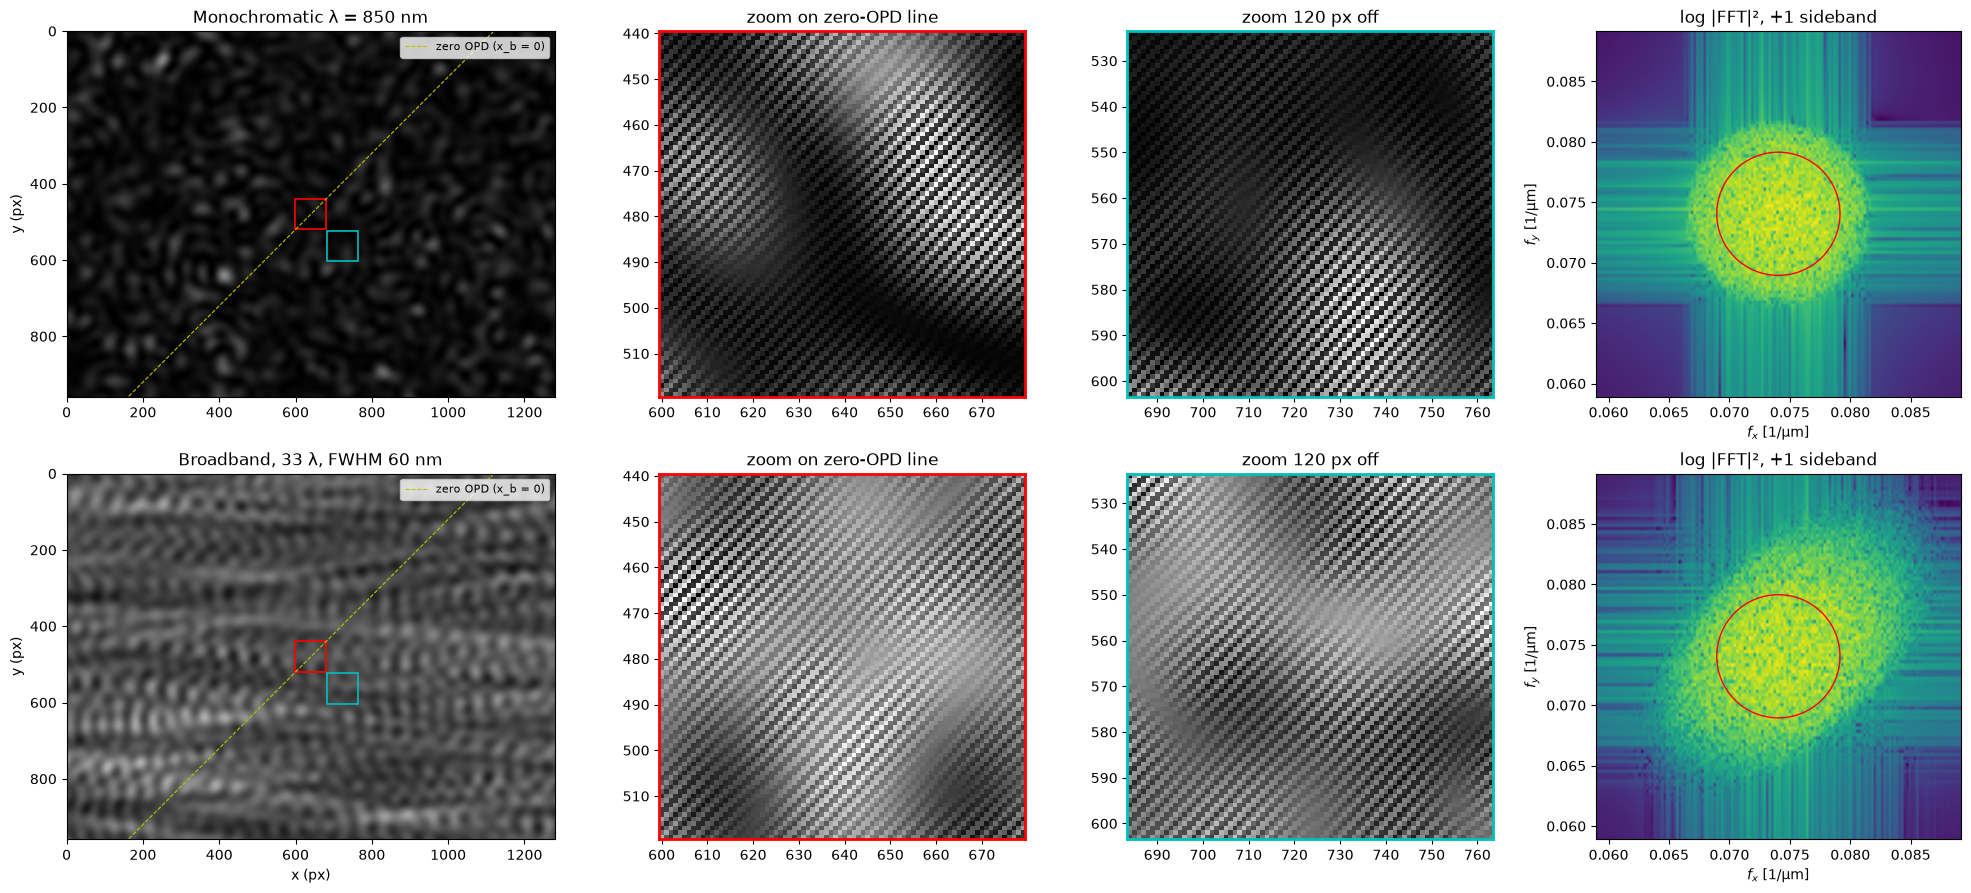

In [14]:
from matplotlib.patches import Rectangle, Circle
from tqdm.auto import tqdm

FRAME = 0                 # which hologram (time step) to build
W = 40                    # zoom half-width in px
OFF = 120                 # off-centre zoom, distance from the zero-OPD line along the biprism normal (px)

k_src, w_src = S_source
lam_src = 2 * np.pi / k_src
j0 = np.argmin(np.abs(lam_src - central_lam))

# Incoherent sum over the source spectrum: I = sum_j S(λ_j) I_j
I_bb, I_mono = 0, None
for j, lam in enumerate(tqdm(lam_src, desc='Wavelengths')):
    U = source_field(X, Y, lam, w0)
    U = angular_spectrum(U, dx=dx, dy=dy, z=z_M1, lam=lam) * P_M1
    U = angular_spectrum(U, dx=dx, dy=dy, z=z_sample, lam=lam)
    U_ill_j = U[s, s]
    del U

    q_j, th_j = scattering_vector(lam0=lam)
    amps_j = object_amplitudes(layout, trajs, {
        "nucleus": mie_amplitude(1.0, 1.39, 1.36, th_j, lam0=lam),
        "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, th_j, lam0=lam),
        "vesicle": mie_amplitude(0.25, 1.40, 1.36, th_j, lam0=lam)})

    U_after = field_after_sample(FRAME, U_ill_j, Xc, Yc, layout, trajs, amps_j, q_j)
    U_L1, X1_j, Y1_j = fresnel_fft(U_after, Xc, Yc, lam, 2*f1)
    U_L1 = U_L1 * lens_transmitance(X1_j, Y1_j, f1, lam, R1)
    U_IP, Xi_j, Yi_j = fresnel_fft(U_L1, X1_j, Y1_j, lam, 2*f1)
    I_j = camera_hologram(U_IP * pupil(Xi_j, Yi_j, R_IP), Xi_j, Yi_j, lam, f2, xc, yc, theta, d_B)

    I_bb = I_bb + w_src[j] * I_j
    if j == j0:
        I_mono = I_j

np.save('hologram_broadband.npy', I_bb)
plt.imsave('hologram_broadband.png', I_bb, cmap='gray')

# Zoom windows: on the zero-OPD line (sensor centre) and OFF px away from it along the biprism normal
ny, nx = I_bb.shape
e = np.array([np.cos(np.radians(45)), np.sin(np.radians(45))])
centres = {'on zero-OPD line': (nx // 2, ny // 2),
           f'{OFF} px off': (nx // 2 + int(OFF * e[0]), ny // 2 + int(OFF * e[1]))}
colors = ['r', 'c']

# Expected width of the fringe band: about λ/Δλ fringes survive
n_fr = central_lam / fwhm
print(f'coherence length λ²/Δλ = {central_lam**2 / fwhm:.1f} µm  ->  about {n_fr:.0f} fringes, '
      f'a band about {n_fr * Lambda / p:.0f} px wide across the fringes')

# Hologram spectrum around the +1 carrier
fx = np.fft.fftshift(np.fft.fftfreq(nx, p))
fy = np.fft.fftshift(np.fft.fftfreq(ny, p))
c = e / Lambda
r_sb = 1.3 * R_IP / (central_lam * f2)
ix, iy = np.abs(fx - c[0]) <= 3 * r_sb, np.abs(fy - c[1]) <= 3 * r_sb

fig, ax = plt.subplots(2, 4, figsize=(20, 9), gridspec_kw={'width_ratios': [nx / ny, 1, 1, 1]})
for row, (I, label) in enumerate([(I_mono, f'Monochromatic λ = {central_lam*1e3:.0f} nm'),
                                  (I_bb, f'Broadband, {len(lam_src)} λ, FWHM {fwhm*1e3:.0f} nm')]):
    a = ax[row, 0]
    a.imshow(I, cmap='gray')
    rows = np.arange(ny)
    a.plot(nx // 2 - (rows - ny // 2), rows, 'y--', lw=0.8, label='zero OPD (x_b = 0)')
    a.set(xlim=(0, nx - 1), ylim=(ny - 1, 0), title=label, ylabel='y (px)')
    a.legend(loc='upper right', fontsize=8)

    for col, ((name, (cx, cy)), clr) in enumerate(zip(centres.items(), colors), start=1):
        a.add_patch(Rectangle((cx - W - 0.5, cy - W - 0.5), 2 * W, 2 * W, fill=False, ec=clr, lw=1.2))
        crop = I[cy - W:cy + W, cx - W:cx + W]
        z = ax[row, col]
        z.imshow(crop, cmap='gray', interpolation='nearest', vmin=crop.min(), vmax=crop.max(),
                 extent=[cx - W - 0.5, cx + W - 0.5, cy + W - 0.5, cy - W - 0.5])
        z.set_title(f'zoom {name}')
        for sp in z.spines.values():
            sp.set_color(clr); sp.set_linewidth(2)

    F = np.fft.fftshift(np.fft.fft2(I - I.mean()))
    sp_ax = ax[row, 3]
    sp_ax.imshow(np.log10(np.abs(F[np.ix_(iy, ix)])**2 + 1e-12), origin='lower',
                 extent=[fx[ix][0], fx[ix][-1], fy[iy][0], fy[iy][-1]])
    sp_ax.add_patch(Circle(c, r_sb, fill=False, color='r'))
    sp_ax.set(title='log |FFT|², +1 sideband', xlabel=r'$f_x$ [1/µm]', ylabel=r'$f_y$ [1/µm]')
ax[1, 0].set_xlabel('x (px)')
fig.tight_layout()
fig.savefig('../graphs/hologram_broadband.png', dpi=150)
plt.show()


Wavelengths: 100%|██████████| 33/33 [08:15<00:00, 15.02s/it]


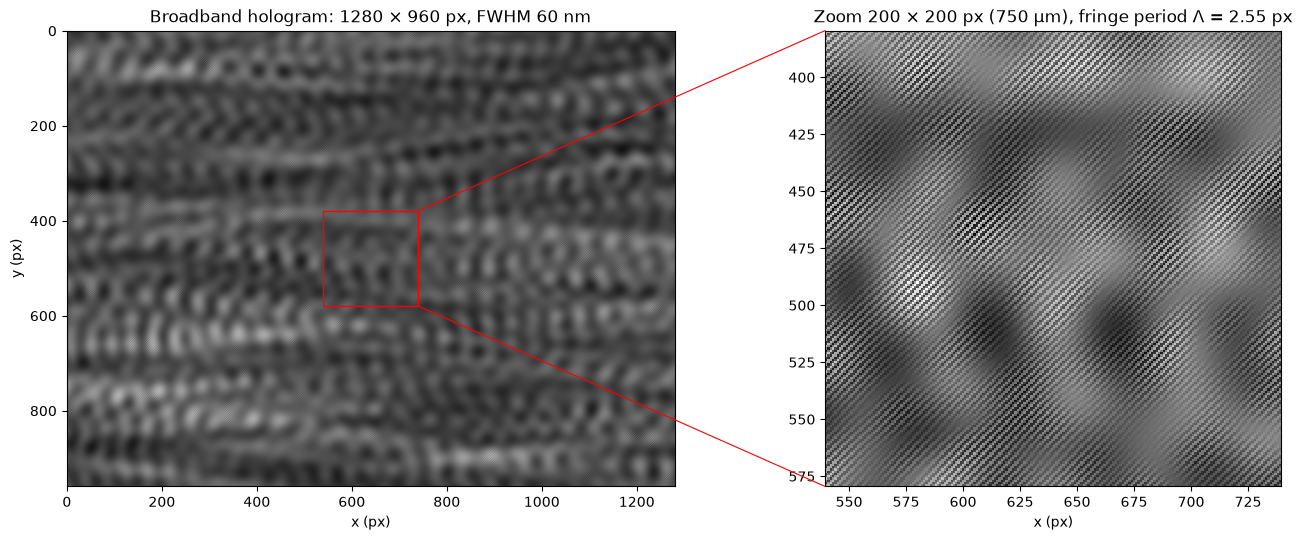

In [15]:
from pathlib import Path
from matplotlib.patches import Rectangle, ConnectionPatch
from tqdm.auto import tqdm

FRAME = 0                 # which hologram (time step)
CX, CY = None, None       # zoom centre in pixels (None = image centre)
W = 100                   # zoom half-width in pixels

# Build the broadband hologram once: incoherent sum over the source spectrum, I = sum_j S(λ_j) I_j
path = Path(f'hologram_broadband_{FRAME}.npy')
if path.exists():
    I_bb = np.load(path)
else:
    k_src, w_src = S_source
    I_bb = 0
    for j, lam in enumerate(tqdm(2 * np.pi / k_src, desc='Wavelengths')):
        U = source_field(X, Y, lam, w0)
        U = angular_spectrum(U, dx=dx, dy=dy, z=z_M1, lam=lam) * P_M1
        U = angular_spectrum(U, dx=dx, dy=dy, z=z_sample, lam=lam)
        U_ill_j = U[s, s]
        del U

        q_j, th_j = scattering_vector(lam0=lam)
        amps_j = object_amplitudes(layout, trajs, {
            "nucleus": mie_amplitude(1.0, 1.39, 1.36, th_j, lam0=lam),
            "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, th_j, lam0=lam),
            "vesicle": mie_amplitude(0.25, 1.40, 1.36, th_j, lam0=lam)})

        U_after = field_after_sample(FRAME, U_ill_j, Xc, Yc, layout, trajs, amps_j, q_j)
        U_L1, X1_j, Y1_j = fresnel_fft(U_after, Xc, Yc, lam, 2*f1)
        U_L1 = U_L1 * lens_transmitance(X1_j, Y1_j, f1, lam, R1)
        U_IP, Xi_j, Yi_j = fresnel_fft(U_L1, X1_j, Y1_j, lam, 2*f1)
        I_bb = I_bb + w_src[j] * camera_hologram(U_IP * pupil(Xi_j, Yi_j, R_IP), Xi_j, Yi_j,
                                                 lam, f2, xc, yc, theta, d_B)
    np.save(path, I_bb)
    plt.imsave(path.with_suffix('.png'), I_bb, cmap='gray')

# Same plot as the monochromatic hologram
ny, nx = I_bb.shape
cx = nx // 2 if CX is None else CX
cy = ny // 2 if CY is None else CY
x0, x1 = cx - W - 0.5, cx + W - 0.5
y0, y1 = cy - W - 0.5, cy + W - 0.5
crop = I_bb[max(cy - W, 0):cy + W, max(cx - W, 0):cx + W]

fig, (ax, axz) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [nx / ny, 1]})
ax.imshow(I_bb, cmap='gray')
ax.set(title=f'Broadband hologram: {nx} × {ny} px, FWHM {fwhm*1e3:.0f} nm',
       xlabel='x (px)', ylabel='y (px)')

axz.imshow(I_bb, cmap='gray', interpolation='nearest', vmin=crop.min(), vmax=crop.max())
axz.set_xlim(x0, x1)
axz.set_ylim(y1, y0)                                # reversed so up/down matches the full image
axz.set(title=f'Zoom {2*W} × {2*W} px ({2 * W * p:.0f} µm), fringe period Λ = {Lambda / p:.2f} px',
        xlabel='x (px)')

ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='r', lw=1))
for y in (y0, y1):
    fig.add_artist(ConnectionPatch((x1, y), (x0, y), 'data', 'data',
                                   axesA=ax, axesB=axz, color='r', lw=0.8))
fig.tight_layout()
plt.show()
